# Section 1: Exoplanet Data Preparation & Cleaning

## Overview
This notebook performs **Data Preparation and Feature Engineering** on the raw NASA Exoplanet Archive composite table (`pscomppars`), collected in `data_collection.ipynb`. 

The raw dataset contains **6,445 confirmed exoplanets** described across **703 columns** (including upper/lower error bounds, reference identifiers, and measurement provenance flags).

### Objectives:
1. **Feature Selection**: Extract the most critical planetary, orbital, stellar, and discovery features from the 703 raw columns.
2. **Missing Value Recovery**: Utilize fundamental astrophysical laws (Kepler's Third Law and mean spherical density) to recover missing orbital distances and planetary densities.
3. **Measurement Provenance**: Separate empirically measured masses (Radial Velocity, Transit Timing Variations, Astrometry) from model-derived estimates (Mass-Radius relations) to prevent data leakage in subsequent analyses.
4. **Astronomical Taxonomy & Feature Engineering**: Classify planets into standard astrophysical regimes (Terrestrial, Super-Earth, Sub-Neptune, Neptune-like, Gas Giant, Hot Jupiter) and compute log-transformed features for power-law scaling.
5. **Cleaned Dataset Export**: Save the curated dataset as `cleaned_exoplanet_data.csv` for EDA and Machine Learning.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120

print("Data preparation environment initialized successfully!")


Data preparation environment initialized successfully!


## 1.1 Loading the Raw NASA Exoplanet Archive Dataset
We load `exoplanet_data.csv` and inspect its initial shape.


In [2]:
raw_path = 'exoplanet_data.csv'
if not os.path.exists(raw_path):
    raise FileNotFoundError(f"Missing raw dataset: {raw_path}")

# Load full raw dataset
df_raw = pd.read_csv(raw_path, low_memory=False)
print(f"Raw Dataset Dimensions: {df_raw.shape[0]:,} rows x {df_raw.shape[1]:,} columns")


Raw Dataset Dimensions: 6,445 rows x 703 columns


## 1.2 Domain-Driven Feature Selection
From the 703 columns, we select the core astronomical parameters required for physical modeling, statistical analysis, and machine learning:

* **Identification & Discovery**: `pl_name`, `hostname`, `discoverymethod`, `disc_year`, `disc_facility`
* **Planetary Physical Properties**:
  * `pl_bmasse` (Best Planet Mass [Earth Mass])
  * `pl_rade` (Planet Radius [Earth Radii])
  * `pl_dens` (Planet Density [g/cm³])
  * `pl_insol` (Insolation Flux [Earth flux])
  * `pl_eqt` (Equilibrium Temperature [K])
  * `pl_bmassprov` (Mass Provenance: Mass, Msini, M-R relationship)
* **Orbital Properties**:
  * `pl_orbper` (Orbital Period [days])
  * `pl_orbsmax` (Orbit Semi-Major Axis [AU])
  * `pl_orbeccen` (Orbital Eccentricity)
* **Host Star Properties**:
  * `st_teff` (Stellar Effective Temperature [K])
  * `st_rad` (Stellar Radius [Solar Radii])
  * `st_mass` (Stellar Mass [Solar Mass])
  * `st_met` (Stellar Metallicity [dex Fe/H])
  * `st_logg` (Stellar Surface Gravity [log10(cm/s²)])
  * `st_lum` (Stellar Luminosity [log10(Solar)])
* **System & Observational Context**:
  * `sy_snum` (Number of Stars in System)
  * `sy_pnum` (Number of Planets in System)
  * `sy_dist` (Distance from Earth [pc])
  * `sy_vmag` (V-band Magnitude)
  * `sy_gaiamag` (Gaia Magnitude)


In [3]:
selected_columns = [
    'pl_name', 'hostname', 'discoverymethod', 'disc_year', 'disc_facility',
    'pl_bmasse', 'pl_rade', 'pl_dens', 'pl_insol', 'pl_eqt', 'pl_bmassprov',
    'pl_orbper', 'pl_orbsmax', 'pl_orbeccen',
    'st_teff', 'st_rad', 'st_mass', 'st_met', 'st_logg', 'st_lum',
    'sy_snum', 'sy_pnum', 'sy_dist', 'sy_vmag', 'sy_gaiamag'
]

df = df_raw[selected_columns].copy()
print(f"Curated Sub-dataset Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head(3)


Curated Sub-dataset Shape: 6,445 rows x 25 columns


,pl_name,hostname,discoverymethod,disc_year,disc_facility,pl_bmasse,pl_rade,pl_dens,pl_insol,pl_eqt,...,st_rad,st_mass,st_met,st_logg,st_lum,sy_snum,sy_pnum,sy_dist,sy_vmag,sy_gaiamag
0,HD 2039 b,HD 2039,Radial Velocity,2002,Anglo-Australian Telescope,1999.1507,12.7000,5.360000,0.3229,210.84,...,1.190,1.230,0.30,4.38000,0.19390,1,1,85.6922,9.000,8.85974
1,HAT-P-8 b,HAT-P-8,Transit,2008,HATNet,406.8224,15.6926,0.685644,1519.9645,1713.00,...,1.570,1.270,0.01,4.15000,0.51900,3,1,211.5530,10.358,10.14890
2,K2-43 b,K2-43,Transit,2016,K2,18.5000,4.5100,1.110000,49.0000,939.30,...,0.542,0.571,NaN,4.68275,-1.21241,1,2,182.5360,15.748,14.82150


## 1.3 Astrophysical Derivations & Handling Missing Values

### 1. Kepler's Third Law for Semi-Major Axis ($a$)
When orbital period $P$ (days) and stellar mass $M_*$ ($M_\odot$) are known, Kepler's Third Law determines the semi-major axis $a$ in astronomical units (AU):
$$a = \left( M_* \cdot \left(\frac{P}{365.256}\right)^2 \right)^{1/3}$$
This recovers missing distances for planets whose period and host mass are well-constrained.

### 2. Mean Spherical Density ($\rho$)
When planet mass $M_p$ ($M_\oplus$) and radius $R_p$ ($R_\oplus$) are recorded but mean density is missing, we calculate density using Earth's mean density ($\rho_\oplus = 5.514\text{ g/cm}^3$):
$$\rho = 5.514 \times \frac{M_p}{R_p^3} \quad [\text{g/cm}^3]$$

### 3. Disentangling Measured Masses from Model Estimates
The NASA Archive's `pl_bmassprov` column records how the planet's mass was determined:
* `Mass`: Directly measured dynamical mass (e.g., Transit Timing Variations, Astrometry).
* `Msini`: Minimum dynamical mass measured via Radial Velocity Doppler spectroscopy ($M_p \sin i$).
* `M-R relationship`: Mass estimated purely from observed radius via theoretical or empirical scaling laws (e.g., Chen & Kipping 2017).

We create an explicit boolean flag `is_measured_mass` to ensure our later predictive models do not suffer from circular data leakage.


In [4]:
# 1. Recover missing semi-major axis via Kepler's 3rd Law
missing_a_before = df['pl_orbsmax'].isna().sum()
kepler_mask = df['pl_orbsmax'].isna() & df['pl_orbper'].notna() & df['st_mass'].notna()
df.loc[kepler_mask, 'pl_orbsmax'] = (
    df.loc[kepler_mask, 'st_mass'] * (df.loc[kepler_mask, 'pl_orbper'] / 365.256)**2
)**(1/3)
missing_a_after = df['pl_orbsmax'].isna().sum()
print(f"Kepler's 3rd Law recovered {missing_a_before - missing_a_after} missing semi-major axis values. (Remaining missing: {missing_a_after})")

# 2. Recover missing density
missing_dens_before = df['pl_dens'].isna().sum()
dens_mask = df['pl_dens'].isna() & df['pl_bmasse'].notna() & df['pl_rade'].notna()
df.loc[dens_mask, 'pl_dens'] = 5.514 * (df.loc[dens_mask, 'pl_bmasse'] / (df.loc[dens_mask, 'pl_rade']**3))
missing_dens_after = df['pl_dens'].isna().sum()
print(f"Density calculation recovered {missing_dens_before - missing_dens_after} missing density values. (Remaining missing: {missing_dens_after})")

# 3. Mass provenance flag
df['is_measured_mass'] = df['pl_bmassprov'].isin(['Mass', 'Msini', 'Msin(i)/sin(i)'])
print(f"Empirically measured dynamical masses: {df['is_measured_mass'].sum():,} ({df['is_measured_mass'].mean()*100:.1f}%)")
print(f"Model-estimated masses (M-R relationship): {(~df['is_measured_mass']).sum():,} ({(~df['is_measured_mass']).mean()*100:.1f}%)")


Kepler's 3rd Law recovered 484 missing semi-major axis values. (Remaining missing: 8)
Density calculation recovered 75 missing density values. (Remaining missing: 73)
Empirically measured dynamical masses: 3,413 (53.0%)
Model-estimated masses (M-R relationship): 3,032 (47.0%)


## 1.4 Exoplanet Taxonomy & Feature Engineering

We classify exoplanets into canonical astrophysical regimes based on radius $R_p$ ($R_\oplus$) and orbital period $P$ (days):
* **Terrestrial**: $R_p < 1.25\,R_\oplus$ (Rocky cores with thin or no secondary atmospheres)
* **Super-Earth**: $1.25 \le R_p < 2.0\,R_\oplus$ (Dense rocky/iron planets below the Fulton radius valley)
* **Sub-Neptune**: $2.0 \le R_p < 4.0\,R_\oplus$ (Volatile-rich cores with substantial H/He gaseous envelopes)
* **Neptune-like**: $4.0 \le R_p < 6.0\,R_\oplus$ (Ice giants analogous to Uranus/Neptune)
* **Gas Giant**: $R_p \ge 6.0\,R_\oplus$ with $P \ge 10\,\text{days}$ (Massive Jovian planets at moderate-to-wide orbits)
* **Hot Jupiter**: $R_p \ge 6.0\,R_\oplus$ with $P < 10\,\text{days}$ (Puffier gas giants in extreme proximity to their host star)

*(When radius is missing, we use mass thresholds $M_p < 2\,M_\oplus$, $2-10\,M_\oplus$, $10-50\,M_\oplus$, and $\ge 50\,M_\oplus$.)*

We also compute **logarithmic transformations** (base 10) for quantities spanning multiple orders of magnitude.


In [5]:
def classify_exoplanet(row):
    r = row['pl_rade']
    p = row['pl_orbper']
    m = row['pl_bmasse']
    
    if pd.notna(r):
        if r >= 6.0:
            return 'Hot Jupiter' if (pd.notna(p) and p < 10.0) else 'Gas Giant'
        elif r >= 4.0:
            return 'Neptune-like'
        elif r >= 2.0:
            return 'Sub-Neptune'
        elif r >= 1.25:
            return 'Super-Earth'
        else:
            return 'Terrestrial'
    if pd.notna(m):
        if m >= 50.0:
            return 'Hot Jupiter' if (pd.notna(p) and p < 10.0) else 'Gas Giant'
        elif m >= 10.0:
            return 'Neptune-like'
        elif m >= 2.0:
            return 'Super-Earth'
        else:
            return 'Terrestrial'
    return 'Unknown'

df['planet_type'] = df.apply(classify_exoplanet, axis=1)

# Compute base-10 log transforms for physically skewed parameters
log_candidates = ['pl_bmasse', 'pl_rade', 'pl_dens', 'pl_orbper', 'pl_orbsmax', 'pl_insol', 'st_teff', 'st_mass', 'sy_dist']
for col in log_candidates:
    df['log_' + col] = np.log10(df[col].clip(lower=1e-6))

# Display planetary class breakdown
class_counts = df['planet_type'].value_counts()
print("Exoplanet Classification Breakdown:")
print(class_counts.to_string())


Exoplanet Classification Breakdown:
planet_type
Sub-Neptune     2122
Gas Giant       1372
Super-Earth     1213
Hot Jupiter      830
Terrestrial      583
Neptune-like     318
Unknown            7


findfont: Failed to find font weight semibold, now using 700.


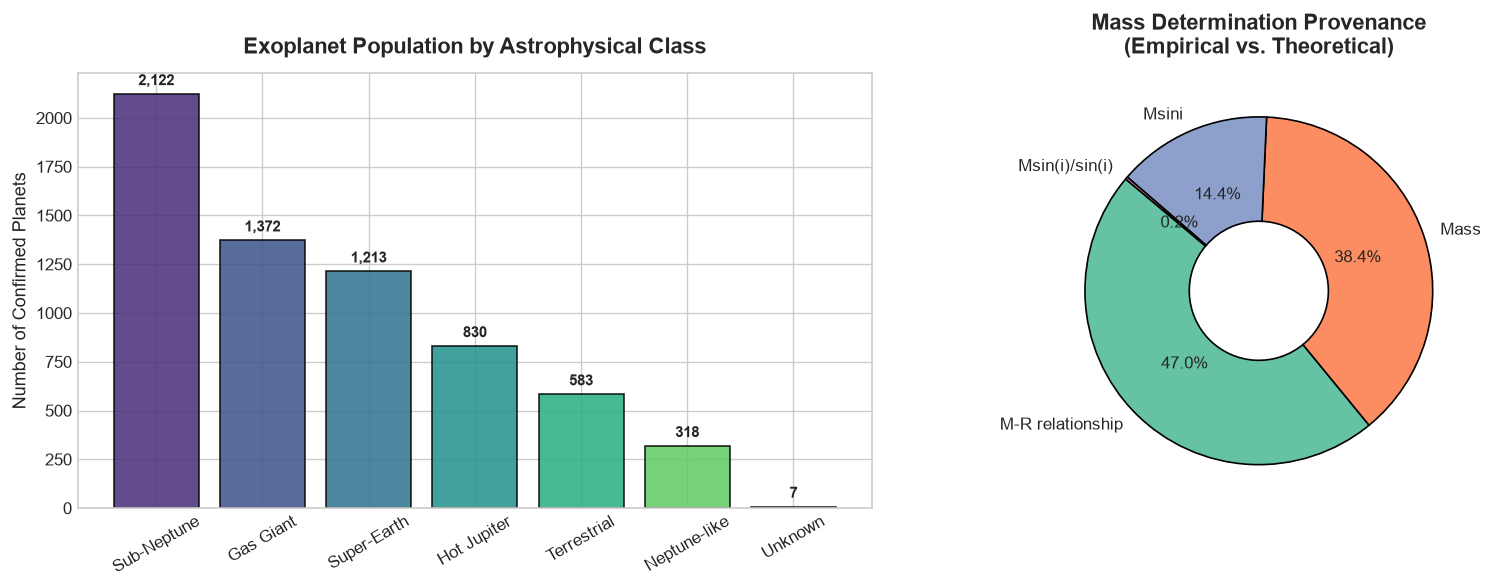

In [6]:
os.makedirs('figures', exist_ok=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Planet Type Distribution
colors = sns.color_palette('viridis', len(class_counts))
bars = ax1.bar(class_counts.index, class_counts.values, color=colors, edgecolor='black', alpha=0.85)
ax1.set_title('Exoplanet Population by Astrophysical Class', fontsize=13, fontweight='bold', pad=12)
ax1.set_ylabel('Number of Confirmed Planets', fontsize=11)
ax1.tick_params(axis='x', rotation=30)
for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 30, f"{yval:,}", ha='center', va='bottom', fontsize=9, fontweight='semibold')

# 2. Mass Provenance Breakdown
prov_counts = df['pl_bmassprov'].value_counts()
ax2.pie(prov_counts.values, labels=prov_counts.index, autopct='%1.1f%%',
        colors=sns.color_palette('Set2', len(prov_counts)), startangle=140,
        wedgeprops=dict(edgecolor='black', width=0.6))
ax2.set_title('Mass Determination Provenance\n(Empirical vs. Theoretical)', fontsize=13, fontweight='bold', pad=12)

plt.tight_layout()
plt.savefig('figures/01_data_preparation_overview.png', dpi=300)
plt.show()


## 1.5 Quality Verification & Cleaned Dataset Export

We check the missing rate profile of the final curated features and export `cleaned_exoplanet_data.csv`.


In [7]:
# Missing value summary in cleaned dataset
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Pct (%)': (df.isnull().mean() * 100).round(2)
})
print("Missing Value Profile of Cleaned Dataset:")
print(missing_summary[missing_summary['Missing Count'] > 0].to_string())

# Export cleaned dataset
clean_path = 'cleaned_exoplanet_data.csv'
df.to_csv(clean_path, index=False)
file_size_mb = os.path.getsize(clean_path) / (1024 * 1024)
print(f"\nSuccessfully exported '{clean_path}' ({file_size_mb:.2f} MB, {df.shape[0]:,} rows x {df.shape[1]} columns).")


Missing Value Profile of Cleaned Dataset:
                Missing Count  Missing Pct (%)
pl_bmasse                  31             0.48
pl_rade                    50             0.78
pl_dens                    73             1.13
pl_insol                  592             9.19
pl_eqt                    536             8.32
pl_orbper                 353             5.48
pl_orbsmax                  8             0.12
pl_orbeccen              1066            16.54
st_teff                   307             4.76
st_rad                    331             5.14
st_mass                     9             0.14
st_met                    698            10.83
st_logg                   336             5.21
st_lum                    325             5.04
sy_dist                    28             0.43
sy_vmag                   312             4.84
sy_gaiamag                358             5.55
log_pl_bmasse              31             0.48
log_pl_rade                50             0.78
log_pl_dens       